In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels as sm
from statsmodels.discrete.conditional_models import ConditionalLogit

In [9]:
df = pd.read_stata("S1Table.DTA")

In [10]:
df.head()

,start_date,end_date,finished,land_development,q2,q3,agree_survey,involved_planning,role,role_text,...,water_med3,water_high1,water_high2,water_high3,cult_s1,cult_s2,cult_s3,cult_sl1,cult_sl2,cult_sl3
0,22/11/2015 19:49,22/11/2015 19:55,1,1,1,1,1,Yes,Policy_staff,,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,22/11/2015 19:49,22/11/2015 19:55,1,1,1,1,1,Yes,Policy_staff,,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,22/11/2015 19:49,22/11/2015 19:55,1,1,1,1,1,Yes,Policy_staff,,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,22/11/2015 19:49,22/11/2015 19:55,1,1,1,1,1,Yes,Policy_staff,,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,22/11/2015 19:49,22/11/2015 19:55,1,1,1,1,1,Yes,Policy_staff,,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [11]:
print(df.shape)

(2160, 147)


In [12]:
job_distribution = df['role'].value_counts()
print(job_distribution)

n = np.sum(job_distribution)
print(job_distribution / n)

role
Councillor          1584
Policy_staff         216
Compliance_staff      96
Other                 96
Science_staff         12
Name: count, dtype: int64
role
Councillor          0.790419
Policy_staff        0.107784
Compliance_staff    0.047904
Other               0.047904
Science_staff       0.005988
Name: count, dtype: float64


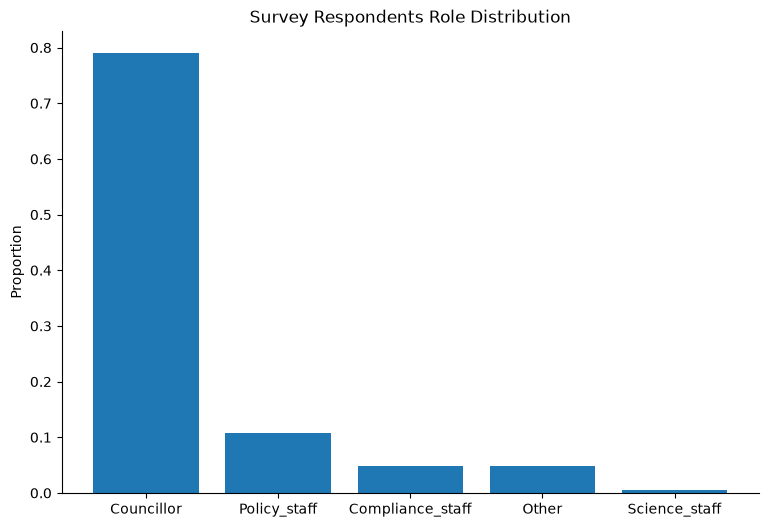

In [13]:
fig, ax = plt.subplots(figsize = (9, 6))

ax.bar(job_distribution.index, job_distribution/n)
ax.set_title('Survey Respondents Role Distribution')
ax.set_ylabel('Proportion')

ax.spines[['top', 'right']].set_visible(False)

Group Characteristics 

Gender Breakdown

In [14]:
n = sum(df['gender'].value_counts())
gender_breakdown = df['gender'].value_counts() / n
print(gender_breakdown)

gender
Male      0.674556
Female    0.325444
Name: count, dtype: float64


Age

In [15]:
print(df['age_group'].unique())
print(df['age_group'].value_counts() / np.sum(df['age_group'].value_counts()))

['30-39', '50-59', '60-69', NaN, '70-80', '40-49', '20-29']
Categories (6, str): ['20-29' < '30-39' < '40-49' < '50-59' < '60-69' < '70-80']
age_group
60-69    0.367742
50-59    0.277419
40-49    0.148387
70-80    0.122581
30-39    0.058065
20-29    0.025806
Name: count, dtype: float64


Personal Residence

In [16]:
residence_breakdown = df['residence_area'].value_counts()
n2 = np.sum(residence_breakdown)

print(residence_breakdown / n2)

residence_area
urban    0.582353
rural    0.417647
Name: count, dtype: float64


City Inhabitants

In [17]:
df['size_town'].value_counts() / np.sum(df['size_town'].value_counts())

size_town
50,000+          0.390533
15,000-50,000    0.289941
5,000-15,000     0.201183
<5,000           0.118343
Name: count, dtype: float64

Number of Responses

Drop Respondents who are listed as having not finished (finished == 0)

In [18]:
row_index = df[df['finished'] == 0].index
df.drop(index=row_index, inplace=True)

Finding IDs of participants who saw the same choice set more than once

In [19]:
unique_choices = df.groupby('id')['choice_variables'].unique()
num_unique = pd.Series((len(v) for v in unique_choices), index=unique_choices.index)
not_complete_id = num_unique[(num_unique == 2) | (num_unique == 3)].index
print(not_complete_id)
print(len(not_complete_id))

Index([22.0, 32.0, 60.0, 89.0, 111.0, 123.0, 158.0], dtype='float32', name='id')
7


In [20]:
df[np.isin(df['id'], not_complete_id)]['role'].value_counts()

role
Councillor          60
Compliance_staff    12
Other               12
Policy_staff         0
Science_staff        0
Name: count, dtype: int64

Dropping these Participants

In [21]:
df_index = df[df['id'].isin(not_complete_id.values)].index
df.drop(df_index, inplace=True)

This gives the same number of respondents that the paper works with

In [22]:
print(df['alternative_choice'].sum() / 4)
print(len(df['id'].unique()))

164.0
164


In [23]:
df['role'].value_counts()

role
Councillor          1452
Policy_staff         216
Compliance_staff      84
Other                 84
Science_staff         12
Name: count, dtype: int64

Reproduce Figure 1

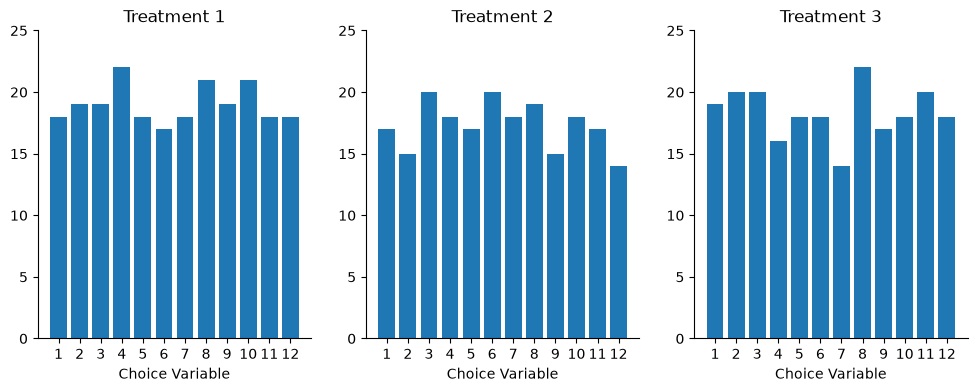

In [24]:
treatments = ['Treatment 1', 'Treatment 2', 'Treatment 3']
y_ticks = [0, 5, 10, 15, 20, 25]

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

for i in range(len(treatments)):
    a = df[df['treatment'] == treatments[i]]['choice_variables'].value_counts() / 3
    x = a.index
    y = a.values
    ax[i].bar(x, y)
    ax[i].set_title(treatments[i])
    ax[i].set_xlabel('Choice Variable')
    ax[i].set_xticks(x)
    ax[i].set_yticks(y_ticks)
    ax[i].spines[['right', 'top']].set_visible(False)

Reconstruct Interaction Terms needed for Regression

In [25]:
df['water_low3'] = df['treatment_3'] * df['wat_low']
df['dev_high23'] = (df['treatment_2'] + df['treatment_3']) * df['dev_high']
df['dev_lim23'] = (df['treatment_2'] + df['treatment_3']) * df['dev_limited']
df['dev_com23'] = (df['treatment_2'] + df['treatment_3']) * df['dev_com']

C:\Users\akare\AppData\Local\Temp\ipykernel_35200\4279210047.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['water_low3'] = df['treatment_3'] * df['wat_low']
C:\Users\akare\AppData\Local\Temp\ipykernel_35200\4279210047.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['dev_high23'] = (df['treatment_2'] + df['treatment_3']) * df['dev_high']
C:\Users\akare\AppData\Local\Temp\ipykernel_35200\4279210047.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many t

In [26]:
vars = ['id', 'treatment', 'treatment_1', 'treatment_2', 'treatment_3', 'choice_set', 'choice_variable', 'alternatives', 'alternative_choice', 
        'development', 'waterquality', 'cult_impact', 'dev_none', 'dev_limited', 'dev_high',
       'dev_com', 'wat_high', 'wat_med', 'wat_low', 'cult_none', 'cult_s',
       'cult_sl', 'dev_lim1', 'dev_lim2', 'dev_lim3', 'dev_high1', 'dev_high2',
       'dev_high3', 'dev_com1', 'dev_com2', 'dev_com3', 'water_med1',
       'water_med2', 'water_med3', 'water_high1', 'water_high2', 'water_high3',
       'cult_s1', 'cult_s2', 'cult_s3', 'cult_sl1', 'cult_sl2', 'cult_sl3']

In [27]:
#consider dev_none, water_high, and cult_none as base cases (drop these to avoid perfect colinearity)
main = ['dev_limited', 'dev_high', 'dev_com', 'wat_med', 'wat_low', 'cult_s', 'cult_sl']
#interaction terms
#was money shown for this attribute
treatment_var = ['dev_lim23', 'dev_high23', 'dev_com23', 'water_med3', 'water_low3']

Conditional Logit Model (All)

In [28]:
model_3 = ConditionalLogit(df['alternative_choice'], df[main + treatment_var], groups=df['choice_variables']).fit()

In [29]:
model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                  Conditional Logit Model Regression Results                  
==============================================================================
Dep. Variable:     alternative_choice   No. Observations:                 1968
Model:               ConditionalLogit   No. groups:                         12
Log-Likelihood:               -852.92   Min group size:                    150
Method:                          BFGS   Max group size:                    186
Date:                Sun, 08 Nov 2026   Mean group size:                 164.0
Time:                        11:13:49                                         
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
dev_limited     4.2588      0.667      6.385      0.000       2.951       5.566
dev_high        4.5525      0.693      6.570      0.000       3.194       5.911
dev_com         4.1139      0.518      7.938      0.000       3.098       5.130
wat_med        -3.9534      0.342    -11.548      0.000      -4.624      -3.282
wat_low        -6.1361      0.520    -11.794      0.000      -7.156      -5.116
cult_s         -0.8215      0.469     -1.751      0.080      -1.741       0.098
cult_sl        -1.6726      0.516     -3.242      0.001      -2.684      -0.661
dev_lim23       0.2054      0.272      0.754      0.451      -0.328       0.739
dev_high23      0.6995      0.295      2.370      0.018       0.121       1.278
dev_com23       0.3052      0.286      1.067      0.286      -0.255       0.866
water_med3     -0.4733      0.267     -1.775      0.076      -0.996       0.049
water_low3     -0.9145      0.528     -1.733      0.083      -1.949       0.120
===============================================================================
"""

In [30]:
#create dataframe including only Councillors
df_c = df[df['role'] == 'Councillor']

Conditional Logit (Councillors)

In [31]:
model_4 = ConditionalLogit(df_c['alternative_choice'], df_c[main + treatment_var], groups=df_c['choice_variables']).fit()

In [32]:
model_4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                  Conditional Logit Model Regression Results                  
==============================================================================
Dep. Variable:     alternative_choice   No. Observations:                 1452
Model:               ConditionalLogit   No. groups:                         12
Log-Likelihood:               -628.83   Min group size:                     93
Method:                          BFGS   Max group size:                    147
Date:                Sun, 08 Nov 2026   Mean group size:                 121.0
Time:                        11:14:09                                         
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
dev_limited     4.4077      0.768      5.742      0.000       2.903       5.912
dev_high        4.8864      0.798      6.125      0.000       3.323       6.450
dev_com         4.4458      0.599      7.425      0.000       3.272       5.619
wat_med        -3.9919      0.397    -10.056      0.000      -4.770      -3.214
wat_low        -6.3900      0.617    -10.364      0.000      -7.598      -5.182
cult_s         -0.8638      0.534     -1.619      0.106      -1.910       0.182
cult_sl        -2.0032      0.589     -3.403      0.001      -3.157      -0.849
dev_lim23       0.0242      0.319      0.076      0.939      -0.600       0.649
dev_high23      0.6541      0.346      1.892      0.059      -0.024       1.332
dev_com23       0.2090      0.329      0.635      0.526      -0.436       0.854
water_med3     -0.2746      0.303     -0.905      0.365      -0.869       0.320
water_low3     -0.5769      0.557     -1.037      0.300      -1.668       0.514
===============================================================================
"""